# Olist E-commerce · Análisis en Python
**Perfilado de datos, retraso vs. satisfacción y segmentación RFM**

Este cuaderno lee los CSV originales de Kaggle (*Brazilian E-Commerce Public Dataset by Olist*), reproduce las vistas de MySQL
(`v_reviews_pedido`, `v_ventas`, `v_pedidos`), valida los KPIs oficiales del proyecto y **genera las tablas que alimentan el dashboard de Power BI**:
`v_pedidos.csv`, `v_ventas.csv`, `rfm_clientes.csv` y `retraso_pedidos.csv`.

**Criterios del proyecto**
- Solo pedidos con estado `delivered`.
- Las ventas son `price` (sin flete).
- Los KPIs se calculan **por pedido** (1 fila por pedido en `v_pedidos`).
- Satisfacción por pedido = promedio de las reseñas de ese pedido.

**Cómo usarlo:** sube los CSV de Kaggle a una carpeta de tu Google Drive y ejecuta las celdas en orden (Entorno de ejecución → Ejecutar todo).

## 1. Configuración y carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.max_columns = 30
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
AZUL, ROJO, GRIS = '#1F4E79', '#C0392B', '#8C8C8C'

In [2]:
# Montar Google Drive (Colab te pedirá autorización)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Carpeta de Drive donde guardaste los CSV de Kaggle (ajusta si usaste otro nombre)
RUTA = '/content/drive/MyDrive/00_archivos_csv/'
# Carpeta donde se guardarán los CSV resultantes
SALIDA = '/content/salida/'

import os
os.makedirs(SALIDA, exist_ok=True)

orders    = pd.read_csv(RUTA + 'olist_orders_dataset.csv',
                        parse_dates=['order_purchase_timestamp', 'order_approved_at',
                                     'order_delivered_carrier_date', 'order_delivered_customer_date',
                                     'order_estimated_delivery_date'])
items     = pd.read_csv(RUTA + 'olist_order_items_dataset.csv', parse_dates=['shipping_limit_date'])
reviews   = pd.read_csv(RUTA + 'olist_order_reviews_dataset.csv')
customers = pd.read_csv(RUTA + 'olist_customers_dataset.csv', dtype={'customer_zip_code_prefix': str})
products  = pd.read_csv(RUTA + 'olist_products_dataset.csv')
traduccion = pd.read_csv(RUTA + 'product_category_name_translation.csv')

print('Tablas cargadas correctamente')

Tablas cargadas correctamente


## 2. Perfilado de datos
Antes de analizar: tamaño de cada tabla, valores nulos, duplicados y rango de fechas.

In [5]:
tablas = {'orders': orders, 'order_items': items, 'order_reviews': reviews,
          'customers': customers, 'products': products, 'category_translation': traduccion}

resumen = pd.DataFrame({
    'filas': {k: len(v) for k, v in tablas.items()},
    'columnas': {k: v.shape[1] for k, v in tablas.items()},
    'celdas_nulas': {k: int(v.isna().sum().sum()) for k, v in tablas.items()},
    'filas_duplicadas': {k: int(v.duplicated().sum()) for k, v in tablas.items()},
})
resumen

,filas,columnas,celdas_nulas,filas_duplicadas
orders,99441,8,4908,0
order_items,112650,7,0,0
order_reviews,99224,7,145903,0
customers,99441,5,0,0
products,32951,9,2448,0
category_translation,71,2,0,0


In [6]:
# Valores esperados (comparar con la hoja "Validacion" del Excel y con MySQL)
esperado = {'orders': 99441, 'order_items': 112650, 'order_reviews': 99224,
            'customers': 99441, 'products': 32951, 'category_translation': 71}
for k, v in esperado.items():
    ok = len(tablas[k]) == v
    print(('OK ' if ok else 'REVISAR ') + f'{k}: {len(tablas[k]):,} filas (esperado {v:,})')

OK orders: 99,441 filas (esperado 99,441)
OK order_items: 112,650 filas (esperado 112,650)
OK order_reviews: 99,224 filas (esperado 99,224)
OK customers: 99,441 filas (esperado 99,441)
OK products: 32,951 filas (esperado 32,951)
OK category_translation: 71 filas (esperado 71)


In [7]:
# Nulos por columna en orders (los pedidos no entregados no tienen fecha de entrega)
orders.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [8]:
# Estado de los pedidos
estados = orders['order_status'].value_counts()
print(estados)
print(f"\nRango de compras: {orders['order_purchase_timestamp'].min():%Y-%m-%d} a {orders['order_purchase_timestamp'].max():%Y-%m-%d}")

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Rango de compras: 2016-09-04 a 2018-10-17


In [9]:
# Calidad en reseñas: un mismo pedido puede tener más de una reseña
# (por eso se promedia por pedido antes de unir con ventas)
rev_por_pedido = reviews.groupby('order_id').size()
print(f"Pedidos con reseña: {len(rev_por_pedido):,}")
print(f"Pedidos con más de 1 reseña: {(rev_por_pedido > 1).sum():,}")
print(f"Pedidos sin reseña: {orders['order_id'].nunique() - len(rev_por_pedido):,}")

Pedidos con reseña: 98,673
Pedidos con más de 1 reseña: 547
Pedidos sin reseña: 768


## 3. Construcción de las tablas analíticas
Es el equivalente en Python de `v_reviews_pedido`, `v_ventas` y `v_pedidos`.

In [10]:
# 3.1 Puntaje promedio por pedido (evita duplicar ventas por reseñas repetidas)
rev_pedido = (reviews.groupby('order_id', as_index=False)['review_score'].mean())

# 3.2 v_ventas: 1 fila por ítem vendido, solo pedidos entregados
entregados = orders[orders['order_status'] == 'delivered']

v_ventas = (entregados
    .merge(items, on='order_id')
    .merge(customers[['customer_id', 'customer_unique_id', 'customer_state', 'customer_city']], on='customer_id')
    .merge(products[['product_id', 'product_category_name']], on='product_id', how='left')
    .merge(traduccion, on='product_category_name', how='left')
    .merge(rev_pedido, on='order_id', how='left'))

v_ventas['categoria'] = (v_ventas['product_category_name_english']
                         .fillna(v_ventas['product_category_name'])
                         .fillna('sin_categoria'))
v_ventas['fecha_compra'] = v_ventas['order_purchase_timestamp'].dt.normalize()
v_ventas['dias_entrega'] = (v_ventas['order_delivered_customer_date'].dt.normalize()
                            - v_ventas['fecha_compra']).dt.days            # igual que DATEDIFF de MySQL
v_ventas['entrega_tardia'] = np.where(
    v_ventas['order_delivered_customer_date'].isna(), np.nan,
    (v_ventas['order_delivered_customer_date'] > v_ventas['order_estimated_delivery_date']).astype(float))

v_ventas = v_ventas.rename(columns={
    'customer_state': 'estado', 'customer_city': 'ciudad',
    'order_delivered_customer_date': 'fecha_entrega',
    'order_estimated_delivery_date': 'fecha_estimada'})[
    ['order_id', 'order_item_id', 'fecha_compra', 'fecha_entrega', 'fecha_estimada',
     'customer_unique_id', 'estado', 'ciudad', 'categoria', 'price', 'freight_value',
     'review_score', 'dias_entrega', 'entrega_tardia']]

print(f'v_ventas: {len(v_ventas):,} ítems · {v_ventas.order_id.nunique():,} pedidos')

v_ventas: 110,197 ítems · 96,478 pedidos


In [11]:
# 3.3 v_pedidos: 1 fila por pedido (base de los KPIs oficiales)
v_pedidos = (v_ventas.groupby('order_id', as_index=False)
    .agg(customer_unique_id=('customer_unique_id', 'first'),
         fecha_compra=('fecha_compra', 'first'),
         estado=('estado', 'first'),
         ventas=('price', 'sum'),
         flete=('freight_value', 'sum'),
         items=('order_item_id', 'count'),
         dias_entrega=('dias_entrega', 'first'),
         entrega_tardia=('entrega_tardia', 'first'),
         review_score=('review_score', 'first')))
v_pedidos['ventas'] = v_pedidos['ventas'].round(2)
v_pedidos['flete'] = v_pedidos['flete'].round(2)

print(f'v_pedidos: {len(v_pedidos):,} pedidos')
v_pedidos.head()

v_pedidos: 96,478 pedidos


,order_id,customer_unique_id,fecha_compra,estado,ventas,flete,items,dias_entrega,entrega_tardia,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,871766c5855e863f6eccc05f988b23cb,2017-09-13,RJ,58.90,13.29,1,7.00,0.00,5.00
1,00018f77f2f0320c557190d7a144bdd3,eb28e67c4c0b83846050ddfb8a35d051,2017-04-26,SP,239.90,19.93,1,16.00,0.00,4.00
2,000229ec398224ef6ca0657da4fc703e,3818d81c6709e39d06b2738a8d3a2474,2018-01-14,MG,199.00,17.87,1,8.00,0.00,5.00
3,00024acbcdf0a6daa1e931b038114c75,af861d436cfc08b2c2ddefd0ba074622,2018-08-08,SP,12.99,12.79,1,6.00,0.00,4.00
4,00042b26cf59d7ce69dfabb4e55b4fd9,64b576fb70d441e8f1b2d7d446e483c5,2017-02-04,SP,199.90,18.14,1,25.00,0.00,5.00


## 4. Validación de KPIs oficiales
Los valores deben coincidir con el dashboard de Power BI, el PDF y el README.

In [12]:
kpis = {
    'Ventas totales (sin flete)': (v_pedidos['ventas'].sum(), 13221498.11, 2),
    'Pedidos':                    (v_pedidos['order_id'].nunique(), 96478, 0),
    'Ticket promedio':            (v_pedidos['ventas'].mean(), 137.04, 2),
    'Días de entrega (prom.)':    (v_pedidos['dias_entrega'].mean(), 12.5, 1),
    '% entregas tardías':         (100 * v_pedidos['entrega_tardia'].mean(), 8.11, 2),
    'Satisfacción (por pedido)':  (v_pedidos['review_score'].mean(), 4.16, 2),
    'Clientes únicos':            (v_pedidos['customer_unique_id'].nunique(), 93358, 0),
}
filas = []
for nombre, (calc, oficial, dec) in kpis.items():
    filas.append({'KPI': nombre, 'Python': round(calc, dec), 'Oficial': oficial,
                  'Coincide': 'OK' if round(calc, dec) == oficial else 'REVISAR'})
pd.DataFrame(filas)

,KPI,Python,Oficial,Coincide
0,Ventas totales (sin flete),"13,221,498.11","13,221,498.11",OK
1,Pedidos,"96,478.00","96,478.00",OK
2,Ticket promedio,137.04,137.04,OK
3,Días de entrega (prom.),12.50,12.50,OK
4,% entregas tardías,8.11,8.11,OK
5,Satisfacción (por pedido),4.16,4.16,OK
6,Clientes únicos,"93,358.00","93,358.00",OK


In [13]:
# Diferencia de base: la satisfacción cambia según cómo se promedie (se declara en el README)
print(f"Satisfacción por pedido : {v_pedidos['review_score'].mean():.2f}")
print(f"Satisfacción por ítem   : {v_ventas['review_score'].mean():.2f}")
print(f"Satisfacción por reseña : {reviews['review_score'].mean():.2f}  (sobre las {len(reviews):,} reseñas)")

Satisfacción por pedido : 4.16
Satisfacción por ítem   : 4.08
Satisfacción por reseña : 4.09  (sobre las 99,224 reseñas)


## 5. Retraso vs. satisfacción → `retraso_pedidos`
Se analizan los pedidos entregados que tienen reseña y fecha de entrega.
`dias_retraso` = fecha de entrega real − fecha estimada (negativo = llegó antes de lo prometido).

In [14]:
entregas = (orders[orders['order_status'] == 'delivered']
            [['order_id', 'order_delivered_customer_date', 'order_estimated_delivery_date']]
            .merge(rev_pedido, on='order_id')
            .dropna(subset=['order_delivered_customer_date', 'order_estimated_delivery_date']))

entregas['dias_retraso'] = ((entregas['order_delivered_customer_date']
                             - entregas['order_estimated_delivery_date']) / pd.Timedelta(days=1))

grupos = ['8+ días antes', '0-7 días antes', '1-3 días tarde', '4-7 días tarde', '8-14 días tarde', '15+ días tarde']
cortes = [-np.inf, -8, 0, 3, 7, 14, np.inf]
entregas['grupo'] = pd.cut(entregas['dias_retraso'], bins=cortes, labels=grupos, right=True)
entregas['orden'] = entregas['grupo'].cat.codes + 1

retraso_pedidos = entregas[['order_id', 'dias_retraso', 'grupo', 'orden']].copy()
retraso_pedidos['grupo'] = retraso_pedidos['grupo'].astype(str)
print(f'retraso_pedidos: {len(retraso_pedidos):,} pedidos (esperado 95.824)')

retraso_pedidos: 95,824 pedidos (esperado 95.824)


In [15]:
tabla_retraso = (entregas.groupby(['orden', 'grupo'], observed=True)
                 .agg(pedidos=('order_id', 'count'), nota_promedio=('review_score', 'mean'))
                 .reset_index())
tabla_retraso

,orden,grupo,pedidos,nota_promedio
0,1,8+ días antes,66129,4.32
1,2,0-7 días antes,22034,4.21
2,3,1-3 días tarde,2636,3.77
3,4,4-7 días tarde,1773,2.32
4,5,8-14 días tarde,1748,1.75
5,6,15+ días tarde,1504,1.71


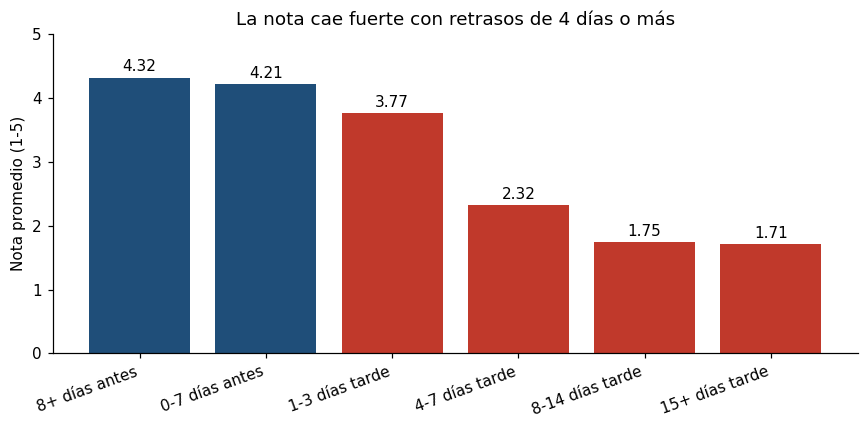

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
colores = [AZUL if o <= 2 else ROJO for o in tabla_retraso['orden']]
barras = ax.bar(tabla_retraso['grupo'].astype(str), tabla_retraso['nota_promedio'], color=colores)
ax.bar_label(barras, fmt='%.2f', padding=2)
ax.set_ylim(0, 5)
ax.set_ylabel('Nota promedio (1-5)')
ax.set_title('La nota cae fuerte con retrasos de 4 días o más')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

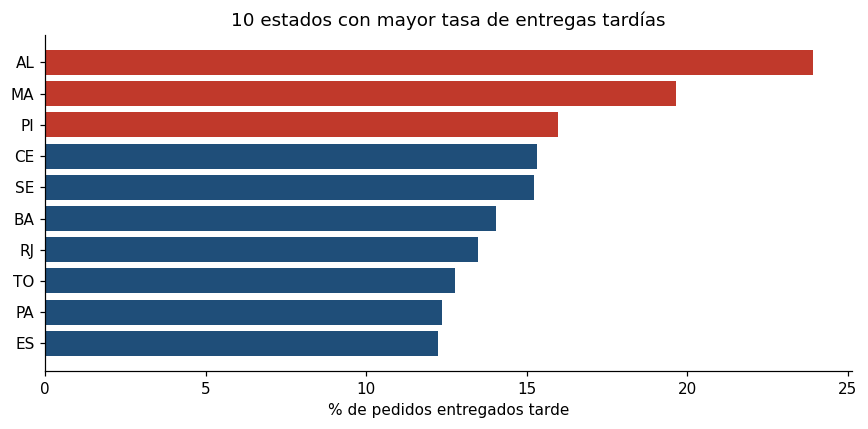

,pedidos,pct_tardias
estado,,
AL,397,23.93
MA,717,19.67
PI,476,15.97
CE,1279,15.32
SE,335,15.22
BA,3256,14.04
RJ,12350,13.47
TO,274,12.77
PA,946,12.37


In [17]:
# Estados con mayor tasa de entregas tardías (excluye estados con pocos pedidos)
por_estado = (v_pedidos.groupby('estado')
              .agg(pedidos=('order_id', 'count'), pct_tardias=('entrega_tardia', lambda s: 100 * s.mean()))
              .query('pedidos >= 100')
              .sort_values('pct_tardias', ascending=False)
              .head(10))

fig, ax = plt.subplots(figsize=(8, 4))
colores = [ROJO if i < 3 else AZUL for i in range(len(por_estado))]
ax.barh(por_estado.index[::-1], por_estado['pct_tardias'][::-1], color=colores[::-1])
ax.set_xlabel('% de pedidos entregados tarde')
ax.set_title('10 estados con mayor tasa de entregas tardías')
plt.tight_layout()
plt.show()
por_estado

## 6. Segmentación RFM → `rfm_clientes`
- **Recencia:** días desde la última compra hasta el día siguiente a la última fecha del dataset.
- **Frecuencia:** número de pedidos del cliente.
- **Monto:** ventas acumuladas del cliente (sin flete).

**Puntajes:** recencia y monto en quintiles (5 = mejor). Frecuencia: 1 pedido = 1, 2 pedidos = 3, 3 o más = 5.

**Segmentos**
| Segmento | Regla |
|---|---|
| Recurrentes | 2 o más pedidos |
| En riesgo de alto valor | 1 pedido, compró hace mucho (R ≤ 2) y gastó alto (M ≥ 4) |
| Perdidos | 1 pedido, compró hace mucho (R ≤ 2) y gastó poco (M ≤ 3) |
| Ocasionales | 1 pedido, recencia media (R = 3) |
| Nuevos de alto valor | 1 pedido, compra reciente (R ≥ 4) y gasto alto (M ≥ 4) |
| Nuevos | 1 pedido, compra reciente (R ≥ 4) y gasto bajo (M ≤ 3) |

In [18]:
fecha_ref = v_pedidos['fecha_compra'].max() + pd.Timedelta(days=1)

rfm = (v_pedidos.groupby('customer_unique_id')
       .agg(ultima_compra=('fecha_compra', 'max'),
            frecuencia=('order_id', 'nunique'),
            monto=('ventas', 'sum')))
rfm['monto'] = rfm['monto'].round(2)
rfm['recencia'] = (fecha_ref - rfm['ultima_compra']).dt.days

# rank(method='first') evita errores de qcut por empates
rfm['R'] = pd.qcut(rfm['recencia'].rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['M'] = pd.qcut(rfm['monto'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['F'] = np.where(rfm['frecuencia'] >= 3, 5, np.where(rfm['frecuencia'] == 2, 3, 1))

def segmentar(f):
    if f['F'] >= 3:
        return 'Recurrentes'
    if f['R'] <= 2:
        return 'En riesgo de alto valor' if f['M'] >= 4 else 'Perdidos'
    if f['R'] == 3:
        return 'Ocasionales'
    return 'Nuevos de alto valor' if f['M'] >= 4 else 'Nuevos'

rfm['segmento'] = rfm.apply(segmentar, axis=1)
rfm_clientes = rfm.reset_index()[['customer_unique_id', 'recencia', 'frecuencia', 'monto', 'R', 'M', 'F', 'segmento']]
print(f'rfm_clientes: {len(rfm_clientes):,} clientes (esperado 93.358)')
rfm_clientes.head()

rfm_clientes: 93,358 clientes (esperado 93.358)


,customer_unique_id,recencia,frecuencia,monto,R,M,F,segmento
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,4,1,Nuevos de alto valor
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,4,1,1,Nuevos
2,0000f46a3911fa3c0805444483337064,538,1,69.00,1,2,1,Perdidos
3,0000f6ccb0745a6a4b88665a16c9f078,322,1,25.99,2,1,1,Perdidos
4,0004aac84e0df4da2b147fca70cf8255,289,1,180.00,2,5,1,En riesgo de alto valor


In [19]:
resumen_rfm = (rfm_clientes.groupby('segmento')
    .agg(clientes=('customer_unique_id', 'count'),
         recencia_prom=('recencia', 'mean'),
         monto_total=('monto', 'sum'),
         ticket_cliente=('monto', 'mean'))
    .sort_values('monto_total', ascending=False))
resumen_rfm['% clientes'] = 100 * resumen_rfm['clientes'] / resumen_rfm['clientes'].sum()
resumen_rfm['% ventas'] = 100 * resumen_rfm['monto_total'] / resumen_rfm['monto_total'].sum()
resumen_rfm

,clientes,recencia_prom,monto_total,ticket_cliente,% clientes,% ventas
segmento,,,,,,
Nuevos de alto valor,14483,92.23,"3,869,193.01",267.15,15.51,29.26
En riesgo de alto valor,13784,395.13,"3,815,846.24",276.83,14.76,28.86
Ocasionales,18070,220.48,"2,347,553.29",129.91,19.36,17.76
Perdidos,22563,395.68,"1,258,051.18",55.76,24.17,9.52
Nuevos,21657,90.10,"1,202,445.64",55.52,23.20,9.09
Recurrentes,2801,220.81,"728,408.75",260.05,3.00,5.51


In [20]:
alto_valor = ['En riesgo de alto valor', 'Nuevos de alto valor']
pct_cli = resumen_rfm.loc[alto_valor, '% clientes'].sum()
pct_ven = resumen_rfm.loc[alto_valor, '% ventas'].sum()
repiten = 100 * (rfm_clientes['frecuencia'] >= 2).mean()
print(f'Los 2 segmentos de alto valor: {pct_cli:.0f}% de los clientes y {pct_ven:.0f}% de las ventas')
print(f'Clientes que repiten: {repiten:.1f}%')

Los 2 segmentos de alto valor: 30% de los clientes y 58% de las ventas
Clientes que repiten: 3.0%


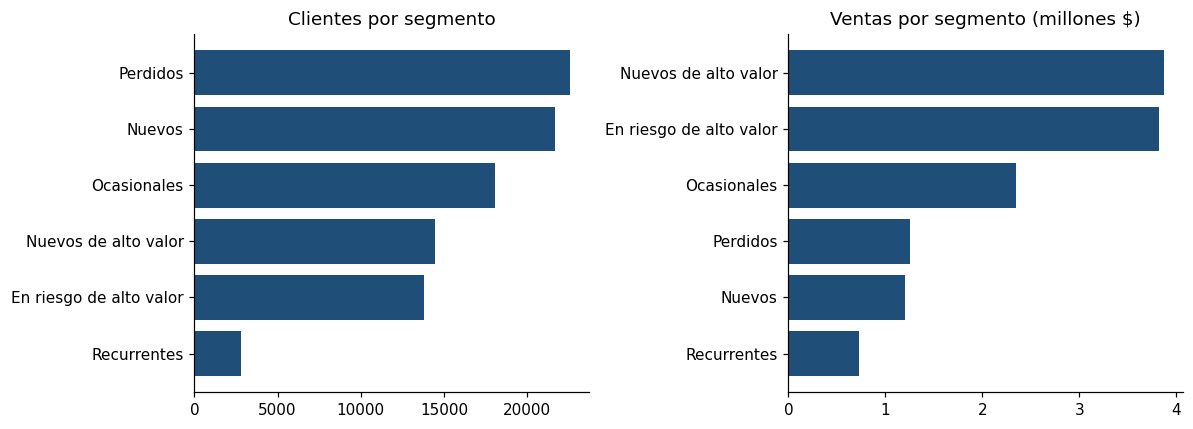

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
orden = resumen_rfm.sort_values('clientes')
axs[0].barh(orden.index, orden['clientes'], color=AZUL)
axs[0].set_title('Clientes por segmento')
orden2 = resumen_rfm.sort_values('monto_total')
axs[1].barh(orden2.index, orden2['monto_total'] / 1e6, color=AZUL)
axs[1].set_title('Ventas por segmento (millones $)')
plt.tight_layout()
plt.show()

## 7. Exportar los CSV para Power BI
Estas tablas son las que carga el archivo `Olist_dashboard.pbix`.

In [22]:
v_pedidos.to_csv(SALIDA + 'v_pedidos.csv', index=False)
v_ventas.to_csv(SALIDA + 'v_ventas.csv', index=False)
rfm_clientes.to_csv(SALIDA + 'rfm_clientes.csv', index=False)
retraso_pedidos.to_csv(SALIDA + 'retraso_pedidos.csv', index=False)

for f in ['v_pedidos', 'v_ventas', 'rfm_clientes', 'retraso_pedidos']:
    print(f'{f}.csv guardado en {SALIDA}')

v_pedidos.csv guardado en /content/salida/
v_ventas.csv guardado en /content/salida/
rfm_clientes.csv guardado en /content/salida/
retraso_pedidos.csv guardado en /content/salida/


In [23]:
# Descargar los 4 archivos como .zip
import shutil
shutil.make_archive('/content/olist_tablas_powerbi', 'zip', SALIDA)
from google.colab import files
files.download('/content/olist_tablas_powerbi.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Conclusiones
- **Retraso y satisfacción:** la nota cae de ~4,2 (entrega a tiempo) a ~2,3 con 4–7 días de retraso y a ~1,7 con más de una semana. Llegar antes casi no mejora la nota. Es una asociación, no prueba causalidad.
- **Geografía:** los estados del Nordeste (AL, MA, PI, CE, SE, BA) tienen las mayores tasas de entregas tardías.
- **Clientes:** los dos segmentos de alto valor concentran el 30 % de los clientes y el 58 % de las ventas; 13.784 clientes de alto valor llevan unos 395 días sin comprar.
- **Recompra:** solo ~3 % de los clientes compró más de una vez.

**Limitaciones:** el RFM depende de la fecha de corte (fin de los datos, ago-2018); si cambian los datos, los resultados cambian y hay que regenerar las tablas y actualizar el reporte.